# Language Identification with Pretrained FastText Vectors & Neural Classifiers
### Introduction to Large Language Models — Assignment 6

This notebook reuses the **language identification dataset from Assignment 1**
(`splits/train.parquet`, `val.parquet`, `test.parquet` — 23 languages, 800/100/100 sentences
each) and classifies each sentence's language using **pretrained FastText Wikipedia word
vectors** (<https://fasttext.cc/docs/en/pretrained-vectors.html>) as features, with five
classifier types:

1. Logistic regression on averaged word vectors
2. MLP with 0, 1, and 2 hidden layers
3. LSTM
4. GRU
5. FastText's own supervised classifier (<https://fasttext.cc/docs/en/supervised-tutorial.html>),
   using the `fasttext` library directly

All five are compared with the **same custom (non-sklearn) macro-F1** implementation, per the
assignment's evaluation constraint.

## A key design decision, up front

FastText publishes **one pretrained model per language** — there's no single multilingual space.
But language ID is exactly the setting where you don't know a sentence's language in advance, so
you can't just "look up the right language's model." Our approach: embed every sentence under
**every available language's** pretrained model, and **concatenate** the results into one
feature vector. The intuition: a Gujarati sentence's tokens will mostly miss the vocabulary of
Hindi/Marathi/Tamil models (near-zero, uninformative regions of the feature vector) while
landing solidly in-vocabulary for the Gujarati model — so which "slice" of the concatenated
vector carries the strongest signal becomes a very direct feature for the classifier. This
matters most for **same-script** languages in the dataset (Hindi/Marathi/Nepali/Sanskrit/
Maithili/Konkani/Sindhi all use Devanagari; Assamese/Bengali share Bengali script;
Kashmiri/Urdu share Arabic script) — script alone can't separate those, but per-language
vocabulary can.

**Coverage caveat:** FastText's Wikipedia vectors only exist for languages with enough
Wikipedia text, which excludes several very low-resource languages in our 23-language dataset
(Bodo, Dogri, Manipuri/Meetei, Khasi, Santali have no `wiki.XX.vec` file). We filter the
classification task down to the ~18 languages that do have pretrained vectors, and say so
explicitly rather than silently dropping them.


## 0. Setup

In [1]:
%pip install -q pandas pyarrow numpy scikit-learn gensim torch fasttext regex tqdm matplotlib requests


Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import re
import time
import pickle
from collections import Counter

import numpy as np
import pandas as pd
import regex
import requests
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from gensim.models import KeyedVectors
from sklearn.decomposition import PCA

import fasttext

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("device:", DEVICE)

SPLITS_DIR = "/Users/vatsalbateriwala/Developer/sem 7/ILLM Lab/Lab-1/splits"                 # written by the Assignment 1 notebook
VECTORS_DIR = "lab6_fasttext_vectors" # cached, truncated pretrained vector files
ARTIFACTS_DIR = "lab6_artifacts"
for d in (VECTORS_DIR, ARTIFACTS_DIR):
    os.makedirs(d, exist_ok=True)

TOP_K_WORDS = 50_000      # only load each language's most frequent TOP_K_WORDS vectors
                           # (.vec files are frequency-sorted, so this is a principled truncation,
                           # and lets us stream-download instead of pulling multi-GB files whole)
PCA_DIM = 30               # per-language dimensionality after PCA, used for the *sequence*
                           # features (LSTM/GRU) -- see \u00a74 for why this differs from \u00a73

# QUICK_TEST restricts to a handful of languages and a tiny vector cap, so the whole notebook's
# *logic* can be checked quickly before running the real, much larger, download+training job.
QUICK_TEST = False
if QUICK_TEST:
    TOP_K_WORDS = 3_000


device: mps


## 1. Load the Assignment 1 dataset & filter to languages with pretrained vectors

Maps each Assignment 1 HF split name (e.g. `guj_Gujr`) to its FastText Wikipedia-vectors
language code (e.g. `gu`), based on <https://fasttext.cc/docs/en/pretrained-vectors.html>.
Entries mapped to `None` have no pretrained wiki vectors and are excluded from this assignment.


In [13]:
# split_name -> fastText wiki-vectors language code, or None if unavailable
FASTTEXT_LANG_CODE = {
    "asm_Beng": "as",
    "ben_Beng": "bn",
    "brx_Deva": None,   # Bodo -- no wiki.XX.vec published
    "doi_Deva": None,   # Dogri -- no wiki.XX.vec published
    "gom_Deva": "gom",  # Goan Konkani
    "guj_Gujr": "gu",
    "hin_Deva": "hi",
    "kan_Knda": "kn",
    "kas_Arab": "ks",
    "mai_Deva": "mai",  # Maithili
    "mal_Mlym": "ml",
    "mar_Deva": "mr",
    "mni_Mtei": None,   # Manipuri/Meetei -- no wiki.XX.vec published
    "npi_Deva": "ne",   # Nepali
    "ory_Orya": "or",   # Oriya
    "pan_Guru": "pa",   # Eastern Punjabi
    "san_Deva": "sa",
    "snd_Deva": "sd",
    "tam_Taml": "ta",
    "tel_Telu": "te",
    "urd_Arab": "ur",
    "khasi": None,      # no wiki.XX.vec published
    "santhali": None,   # no wiki.XX.vec published
}

AVAILABLE_LANGS = sorted(lab for lab, code in FASTTEXT_LANG_CODE.items() if code is not None)
EXCLUDED_LANGS = sorted(lab for lab, code in FASTTEXT_LANG_CODE.items() if code is None)
print(f"{len(AVAILABLE_LANGS)} languages with pretrained FastText vectors: {AVAILABLE_LANGS}")
print(f"{len(EXCLUDED_LANGS)} languages excluded (no pretrained vectors): {EXCLUDED_LANGS}")


18 languages with pretrained FastText vectors: ['asm_Beng', 'ben_Beng', 'gom_Deva', 'guj_Gujr', 'hin_Deva', 'kan_Knda', 'kas_Arab', 'mai_Deva', 'mal_Mlym', 'mar_Deva', 'npi_Deva', 'ory_Orya', 'pan_Guru', 'san_Deva', 'snd_Deva', 'tam_Taml', 'tel_Telu', 'urd_Arab']
5 languages excluded (no pretrained vectors): ['brx_Deva', 'doi_Deva', 'khasi', 'mni_Mtei', 'santhali']


In [14]:
def _load_split(name):
    path = os.path.join(SPLITS_DIR, f"{name}.parquet")
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Couldn't find {path}. Run the Assignment 1 notebook first so it writes "
            f"splits/train.parquet, splits/val.parquet, and splits/test.parquet."
        )
    df = pd.read_parquet(path)
    return df[df["label"].isin(AVAILABLE_LANGS)].reset_index(drop=True)

train_df = _load_split("train")
val_df = _load_split("val")
test_df = _load_split("test")

LABELS = sorted(train_df["label"].unique())
LABEL2IDX = {lab: i for i, lab in enumerate(LABELS)}
IDX2LABEL = {i: lab for lab, i in LABEL2IDX.items()}
N_CLASSES = len(LABELS)

print(f"train: {train_df.shape}  val: {val_df.shape}  test: {test_df.shape}  classes: {N_CLASSES}")


train: (14400, 4)  val: (1800, 4)  test: (1800, 4)  classes: 18


## 2. Download pretrained FastText vectors (truncated, streamed)

Each `wiki.XX.vec` file is a plain-text word2vec-format file: a `<word_count> <dim>` header
line, followed by one `word v1 v2 ... vN` line per word, **ordered by frequency (descending)**.
Because of that ordering, streaming just the first `TOP_K_WORDS` lines gives us the most
frequent (and most useful) words without downloading the whole file — the same
streaming-with-early-stop trick used for the raw IndicCorp downloads in Assignment 1/3. We
rewrite the header's word count to match how many lines we actually kept before handing the
file to Gensim.


In [16]:
FASTTEXT_VEC_URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.{code}.vec"

def _valid_cached_vec(path):
    # Older cache files may contain a bytes representation such as b'300' in the header.
    try:
        with open(path, "r", encoding="utf-8") as f:
            count, dim = f.readline().strip().split()
        int(count)
        int(dim)
        return True
    except (OSError, ValueError):
        return False


def download_truncated_vec(lang_code, top_k=TOP_K_WORDS, cache_dir=VECTORS_DIR, timeout=60):
    cache_path = os.path.join(cache_dir, f"wiki.{lang_code}.top{top_k}.vec")
    print(f"cache_path: {cache_path}  (top_k={top_k}), is file exists: {os.path.exists(cache_path)}")
    if os.path.exists(cache_path):
        if _valid_cached_vec(cache_path):
            # Reuse an existing valid truncated vector file; download only missing files.
            return cache_path
        # Regenerate malformed legacy caches instead of excluding their languages.
        print(f"Invalid cached header in {cache_path}; redownloading.")

    url = FASTTEXT_VEC_URL.format(code=lang_code)
    resp = requests.get(url, stream=True, timeout=timeout)
    resp.raise_for_status()

    # Decode both byte and text response lines so the written header contains plain integers.
    def decode_line(raw):
        return raw.decode("utf-8", errors="ignore") if isinstance(raw, bytes) else raw

    lines_kept = []
    line_iter = (decode_line(raw) for raw in resp.iter_lines())
    header = next(line_iter)  # "<word_count> <dim>"
    header_parts = header.strip().split()
    if len(header_parts) < 2:
        resp.close()
        raise ValueError(f"Invalid FastText header for {lang_code}: {header!r}")
    dim = int(header_parts[1])
    for line in line_iter:
        if not line:
            continue
        lines_kept.append(line)
        if len(lines_kept) >= top_k:
            break
    resp.close()

    with open(cache_path, "w", encoding="utf-8") as f:
        f.write(f"{len(lines_kept)} {dim}\n")
        f.write("\n".join(lines_kept))
    return cache_path


def load_fasttext_vectors(lang_code, top_k=TOP_K_WORDS):
    path = download_truncated_vec(lang_code, top_k=top_k)
    return KeyedVectors.load_word2vec_format(path, binary=False)


lang_vectors = {}   # HF split label -> KeyedVectors
failed_langs = {}
for label in tqdm(AVAILABLE_LANGS, desc="loading FastText vectors"):
    code_ = FASTTEXT_LANG_CODE[label]
    try:
        lang_vectors[label] = load_fasttext_vectors(code_)
    except Exception as e:
        # Failed languages are removed from every downstream dataset and feature.
        failed_langs[label] = str(e)
        print(f"EXCLUDED {label} ({code_}): {e}")

loaded_langs = sorted(lang_vectors.keys())
if not loaded_langs:
    raise RuntimeError("No FastText vector files could be loaded.")

# Remove unavailable or invalid vector languages from the entire notebook pipeline.
failed_labels = sorted(failed_langs)
AVAILABLE_LANGS = loaded_langs
EXCLUDED_LANGS = sorted(set(EXCLUDED_LANGS).union(failed_labels))
for split_name in ("train_df", "val_df", "test_df"):
    split_df = globals()[split_name]
    globals()[split_name] = split_df[split_df["label"].isin(AVAILABLE_LANGS)].reset_index(drop=True)

LABELS = sorted(train_df["label"].unique())
LABEL2IDX = {lab: i for i, lab in enumerate(LABELS)}
IDX2LABEL = {i: lab for lab, i in LABEL2IDX.items()}
N_CLASSES = len(LABELS)

print(f"Loaded pretrained vectors for {len(loaded_langs)}/{len(AVAILABLE_LANGS) + len(failed_labels)} languages")
if failed_labels:
    print(f"Excluded languages (vector load failures): {failed_labels}")
print(f"Filtered dataset: train={train_df.shape}, val={val_df.shape}, test={test_df.shape}, classes={N_CLASSES}")
VECTOR_DIM = next(iter(lang_vectors.values())).vector_size
print("vector dimensionality:", VECTOR_DIM)


loading FastText vectors:   0%|          | 0/18 [00:00<?, ?it/s]

cache_path: lab6_fasttext_vectors/wiki.as.top50000.vec  (top_k=50000), is file exists: True
Invalid cached header in lab6_fasttext_vectors/wiki.as.top50000.vec; redownloading.


loading FastText vectors:   6%|▌         | 1/18 [00:15<04:31, 15.99s/it]

cache_path: lab6_fasttext_vectors/wiki.bn.top50000.vec  (top_k=50000), is file exists: True
Invalid cached header in lab6_fasttext_vectors/wiki.bn.top50000.vec; redownloading.


loading FastText vectors:  11%|█         | 2/18 [00:34<04:37, 17.34s/it]

cache_path: lab6_fasttext_vectors/wiki.gom.top50000.vec  (top_k=50000), is file exists: True
Invalid cached header in lab6_fasttext_vectors/wiki.gom.top50000.vec; redownloading.


... (28 outputs left out)

loading FastText vectors:  94%|█████████▍| 17/18 [02:40<00:04,  4.95s/it]

cache_path: lab6_fasttext_vectors/wiki.ur.top50000.vec  (top_k=50000), is file exists: True


loading FastText vectors: 100%|██████████| 18/18 [02:46<00:00,  9.23s/it]

Loaded pretrained vectors for 18/18 languages
Filtered dataset: train=(14400, 4), val=(1800, 4), test=(1800, 4), classes=18
vector dimensionality: 300


## 3. Sentence features for Logistic Regression / MLP: full-resolution concatenated averages

For each sentence, for each loaded language's vectors, average the vectors of tokens found in
that language's vocabulary (zero vector if none found), then concatenate across all loaded
languages. Feature dimensionality = `len(loaded_langs) * VECTOR_DIM`.


In [17]:
_WORD_RE = regex.compile(r"[\p{L}\p{M}]+|\p{N}+", regex.UNICODE)

def word_tokenize(sentence):
    return _WORD_RE.findall(sentence)


def sentence_vec_under_lang(tokens, kv):
    vecs = [kv[t] for t in tokens if t in kv.key_to_index]
    if not vecs:
        return np.zeros(kv.vector_size, dtype=np.float32)
    return np.mean(vecs, axis=0).astype(np.float32)


def build_concat_features(sentences_text, loaded_langs, lang_vectors, desc="features"):
    tokenized = [word_tokenize(s) for s in sentences_text]
    n = len(tokenized)
    feats = np.zeros((n, len(loaded_langs) * VECTOR_DIM), dtype=np.float32)
    for i, tokens in enumerate(tqdm(tokenized, desc=desc, leave=False)):
        parts = [sentence_vec_under_lang(tokens, lang_vectors[lang]) for lang in loaded_langs]
        feats[i] = np.concatenate(parts)
    return feats


X_train_avg = build_concat_features(train_df["text"].tolist(), loaded_langs, lang_vectors, "train avg-features")
X_val_avg = build_concat_features(val_df["text"].tolist(), loaded_langs, lang_vectors, "val avg-features")
X_test_avg = build_concat_features(test_df["text"].tolist(), loaded_langs, lang_vectors, "test avg-features")

y_train = train_df["label"].map(LABEL2IDX).to_numpy()
y_val = val_df["label"].map(LABEL2IDX).to_numpy()
y_test = test_df["label"].map(LABEL2IDX).to_numpy()

print("X_train_avg:", X_train_avg.shape)


X_train_avg: (14400, 5400)


## 4. Per-token sequence features for LSTM/GRU

LSTM/GRU need one vector **per token**, not one vector per sentence — with
`len(loaded_langs) * VECTOR_DIM` potentially in the thousands, building that at every position
of every sequence is expensive. We first reduce each language's vectors to `PCA_DIM` dimensions
(PCA fit on that language's loaded vocabulary), then build per-token concatenated features from
the reduced vectors. Sequences are padded/truncated to `MAX_SEQ_LEN` tokens.


In [18]:
MAX_SEQ_LEN = 30

# use one fixed component count across every language so per-language vectors concatenate to a
# consistent width -- bounded by the smallest loaded vocabulary across all languages, in case a
# low-resource language's wiki.vec file has fewer than PCA_DIM/5000 words available.
min_vocab = min(len(kv.vectors) for kv in lang_vectors.values())
n_components = min(PCA_DIM, min_vocab, VECTOR_DIM)
if n_components < PCA_DIM:
    print(f"WARNING: smallest loaded vocabulary has only {min_vocab} words; "
          f"using n_components={n_components} instead of PCA_DIM={PCA_DIM} for every language.")

pca_models = {}
for lang in tqdm(loaded_langs, desc="fitting per-language PCA"):
    kv = lang_vectors[lang]
    mat = kv.vectors[: min(len(kv.vectors), 5000)]  # fit on a sample of the loaded vocab
    pca = PCA(n_components=n_components, random_state=RANDOM_SEED)
    pca.fit(mat)
    pca_models[lang] = pca

def token_vec_under_lang(token, kv, pca):
    if token in kv.key_to_index:
        v = kv[token].reshape(1, -1)
        return pca.transform(v)[0].astype(np.float32)
    return np.zeros(pca.n_components_, dtype=np.float32)


def build_sequence_features(sentences_text, loaded_langs, lang_vectors, pca_models,
                             max_len=MAX_SEQ_LEN, desc="sequences"):
    tokenized = [word_tokenize(s)[:max_len] for s in sentences_text]
    per_lang_dim = pca_models[loaded_langs[0]].n_components_
    feat_dim = len(loaded_langs) * per_lang_dim
    n = len(tokenized)
    seqs = np.zeros((n, max_len, feat_dim), dtype=np.float32)
    lengths = np.zeros(n, dtype=np.int64)
    for i, tokens in enumerate(tqdm(tokenized, desc=desc, leave=False)):
        lengths[i] = max(len(tokens), 1)
        for t, tok in enumerate(tokens):
            parts = [token_vec_under_lang(tok, lang_vectors[lang], pca_models[lang]) for lang in loaded_langs]
            seqs[i, t] = np.concatenate(parts)
    return seqs, lengths


X_train_seq, len_train = build_sequence_features(train_df["text"].tolist(), loaded_langs, lang_vectors, pca_models, desc="train seq-features")
X_val_seq, len_val = build_sequence_features(val_df["text"].tolist(), loaded_langs, lang_vectors, pca_models, desc="val seq-features")
X_test_seq, len_test = build_sequence_features(test_df["text"].tolist(), loaded_langs, lang_vectors, pca_models, desc="test seq-features")

print("X_train_seq:", X_train_seq.shape)


fitting per-language PCA: 100%|██████████| 18/18 [00:00<00:00, 56.65it/s]
                                                                           

X_train_seq: (14400, 30, 540)


## 5. Custom macro-F1 (no `sklearn.metrics`, per the assignment's evaluation constraint)

In [19]:
def precision_recall_f1_per_class(y_true, y_pred, n_classes):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    precisions, recalls, f1s = [], [], []
    for c in range(n_classes):
        tp = np.sum((y_pred == c) & (y_true == c))
        fp = np.sum((y_pred == c) & (y_true != c))
        fn = np.sum((y_pred != c) & (y_true == c))
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
        precisions.append(precision); recalls.append(recall); f1s.append(f1)
    return np.array(precisions), np.array(recalls), np.array(f1s)

def macro_f1_score(y_true, y_pred, n_classes):
    _, _, f1s = precision_recall_f1_per_class(y_true, y_pred, n_classes)
    return float(np.mean(f1s)), f1s


## 6. Classifiers 1–4: Logistic Regression, MLP (0/1/2 hidden layers), LSTM, GRU

All four share the same PyTorch training loop shape (cross-entropy loss, Adam, a handful of
epochs) so they're directly comparable. Logistic regression **is** an MLP with 0 hidden layers,
so we implement one configurable `MLPClassifier` and instantiate it with `n_hidden=0` for
logistic regression.


In [20]:
class MLPClassifier(nn.Module):
    """n_hidden=0 reduces to plain (multinomial) logistic regression: a single linear layer."""
    def __init__(self, input_dim, n_classes, n_hidden=0, hidden_dim=256):
        super().__init__()
        layers = []
        in_dim = input_dim
        for _ in range(n_hidden):
            layers.append(nn.Linear(in_dim, hidden_dim))
            layers.append(nn.ReLU())
            in_dim = hidden_dim
        layers.append(nn.Linear(in_dim, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class SequenceClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, n_classes, cell="lstm"):
        super().__init__()
        rnn_cls = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn_cls(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, lengths):
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.rnn(packed)
        h_n = hidden[0] if isinstance(hidden, tuple) else hidden  # LSTM returns (h_n, c_n); GRU returns h_n
        last_hidden = h_n[-1]        # (batch, hidden_dim) -- final layer's hidden state
        return self.fc(last_hidden)


In [21]:
class ArrayDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).long()
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.X[i], self.y[i]

class SequenceDataset(Dataset):
    def __init__(self, X, lengths, y):
        self.X = torch.from_numpy(X).float()
        self.lengths = torch.from_numpy(lengths).long()
        self.y = torch.from_numpy(y).long()
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.X[i], self.lengths[i], self.y[i]


def train_feedforward(model, X_train, y_train, X_val, y_val, epochs=15, batch_size=64, lr=1e-3):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    loader = DataLoader(ArrayDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
    Xv = torch.from_numpy(X_val).float().to(DEVICE)

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            logits = model(xb)
            loss = loss_fn(logits, yb)
            loss.backward()
            opt.step()
            total_loss += loss.item() * xb.size(0)
        model.eval()
        with torch.no_grad():
            val_pred = model(Xv).argmax(dim=1).cpu().numpy()
        val_mf1, _ = macro_f1_score(y_val, val_pred, N_CLASSES)
        print(f"  epoch {epoch:2d}/{epochs}  train_loss={total_loss/len(y_train):.4f}  val_macro_f1={val_mf1:.4f}")
    return model


def train_sequence_model(model, X_train, len_train, y_train, X_val, len_val, y_val,
                          epochs=15, batch_size=64, lr=1e-3):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    loader = DataLoader(SequenceDataset(X_train, len_train, y_train), batch_size=batch_size, shuffle=True)
    Xv = torch.from_numpy(X_val).float().to(DEVICE)
    lv = torch.from_numpy(len_val).long()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for xb, lb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            logits = model(xb, lb)
            loss = loss_fn(logits, yb)
            loss.backward()
            opt.step()
            total_loss += loss.item() * xb.size(0)
        model.eval()
        with torch.no_grad():
            val_pred = model(Xv, lv).argmax(dim=1).cpu().numpy()
        val_mf1, _ = macro_f1_score(y_val, val_pred, N_CLASSES)
        print(f"  epoch {epoch:2d}/{epochs}  train_loss={total_loss/len(y_train):.4f}  val_macro_f1={val_mf1:.4f}")
    return model


@torch.no_grad()
def predict_feedforward(model, X):
    model.eval()
    Xt = torch.from_numpy(X).float().to(DEVICE)
    return model(Xt).argmax(dim=1).cpu().numpy()

@torch.no_grad()
def predict_sequence(model, X, lengths):
    model.eval()
    Xt = torch.from_numpy(X).float().to(DEVICE)
    lt = torch.from_numpy(lengths).long()
    return model(Xt, lt).argmax(dim=1).cpu().numpy()


In [22]:
EPOCHS = 15
results = {}

input_dim_avg = X_train_avg.shape[1]
input_dim_seq = X_train_seq.shape[2]

# ---- 1. Logistic regression == MLP with 0 hidden layers ----
print("=== Logistic Regression (MLP, n_hidden=0) ===")
logreg = MLPClassifier(input_dim_avg, N_CLASSES, n_hidden=0)
logreg = train_feedforward(logreg, X_train_avg, y_train, X_val_avg, y_val, epochs=EPOCHS)
results["LogisticRegression"] = predict_feedforward(logreg, X_test_avg)

# ---- 2. MLP with 1 and 2 hidden layers (0 is already covered above) ----
for n_hidden in (1, 2):
    print(f"=== MLP (n_hidden={n_hidden}) ===")
    mlp = MLPClassifier(input_dim_avg, N_CLASSES, n_hidden=n_hidden, hidden_dim=256)
    mlp = train_feedforward(mlp, X_train_avg, y_train, X_val_avg, y_val, epochs=EPOCHS)
    results[f"MLP(n_hidden={n_hidden})"] = predict_feedforward(mlp, X_test_avg)

# ---- 3. LSTM ----
print("=== LSTM ===")
lstm = SequenceClassifier(input_dim_seq, hidden_dim=128, n_classes=N_CLASSES, cell="lstm")
lstm = train_sequence_model(lstm, X_train_seq, len_train, y_train, X_val_seq, len_val, y_val, epochs=EPOCHS)
results["LSTM"] = predict_sequence(lstm, X_test_seq, len_test)

# ---- 4. GRU ----
print("=== GRU ===")
gru = SequenceClassifier(input_dim_seq, hidden_dim=128, n_classes=N_CLASSES, cell="gru")
gru = train_sequence_model(gru, X_train_seq, len_train, y_train, X_val_seq, len_val, y_val, epochs=EPOCHS)
results["GRU"] = predict_sequence(gru, X_test_seq, len_test)


=== Logistic Regression (MLP, n_hidden=0) ===
  epoch  1/15  train_loss=0.8201  val_macro_f1=0.8942
  epoch  2/15  train_loss=0.3193  val_macro_f1=0.9249
  epoch  3/15  train_loss=0.2529  val_macro_f1=0.9323
  epoch  4/15  train_loss=0.2197  val_macro_f1=0.9322
  epoch  5/15  train_loss=0.1969  val_macro_f1=0.9309
  epoch  6/15  train_loss=0.1813  val_macro_f1=0.9332
  epoch  7/15  train_loss=0.1686  val_macro_f1=0.9381
  epoch  8/15  train_loss=0.1538  val_macro_f1=0.9347
  epoch  9/15  train_loss=0.1460  val_macro_f1=0.9383
  epoch 10/15  train_loss=0.1380  val_macro_f1=0.9372
  epoch 11/15  train_loss=0.1320  val_macro_f1=0.9374
  epoch 12/15  train_loss=0.1248  val_macro_f1=0.9380
  epoch 13/15  train_loss=0.1186  val_macro_f1=0.9357
  epoch 14/15  train_loss=0.1133  val_macro_f1=0.9357
  epoch 15/15  train_loss=0.1070  val_macro_f1=0.9406
=== MLP (n_hidden=1) ===
  epoch  1/15  train_loss=0.4902  val_macro_f1=0.9228
  epoch  2/15  train_loss=0.2064  val_macro_f1=0.9249
  epoch  3/

## 7. Classifier 5: FastText supervised classification

Following <https://fasttext.cc/docs/en/supervised-tutorial.html> directly: write train/val/test
to fastText's `__label__<LABEL> <text>` format, then `fasttext.train_supervised(...)`. This
classifier does **not** use the pretrained wiki vectors at all — it learns its own embeddings
from scratch during supervised training, exactly as in the tutorial (this is normal: FastText's
supervised mode is self-contained and doesn't require external vectors, though it optionally
can be initialized from them via `pretrainedVectors=`, which we don't use here to stay close to
the tutorial's basic recipe).


In [26]:
def write_fasttext_file(df, path):
    with open(path, "w", encoding="utf-8") as f:
        for _, row in df.iterrows():
            text = row["text"].replace("\n", " ")
            f.write(f"__label__{row['label']} {text}\n")

ft_train_path = os.path.join(ARTIFACTS_DIR, "fasttext_train.txt")
ft_val_path = os.path.join(ARTIFACTS_DIR, "fasttext_val.txt")
ft_test_path = os.path.join(ARTIFACTS_DIR, "fasttext_test.txt")
write_fasttext_file(train_df, ft_train_path)
write_fasttext_file(val_df, ft_val_path)
write_fasttext_file(test_df, ft_test_path)

# lr/epoch/wordNgrams per the tutorial's "making the model better" progression
ft_model = fasttext.train_supervised(
    input=ft_train_path, lr=1.0, epoch=25, wordNgrams=2, dim=100, verbose=2,
)


def fasttext_predict_labels(model, texts):
    # Batch prediction avoids fasttext's NumPy 1.x-only np.array(copy=False) path.
    cleaned_texts = [text.replace("\n", " ") for text in texts]
    predicted_labels, _ = model.predict(cleaned_texts)
    return [labels[0].replace("__label__", "") for labels in predicted_labels]


ft_test_pred_labels = fasttext_predict_labels(ft_model, test_df["text"].tolist())
results["FastText"] = np.array([LABEL2IDX[lab] for lab in ft_test_pred_labels])


Read 0M words
Number of words:  82075
Number of labels: 18
Progress: 100.0% words/sec/thread: 1454555 lr:  0.000000 avg.loss:  0.066165 ETA:   0h 0m 0s


## 8. Compare all 5 classifiers

In [27]:
comparison = []
for name, y_pred in results.items():
    mf1, per_class_f1 = macro_f1_score(y_test, y_pred, N_CLASSES)
    acc = float(np.mean(y_pred == y_test))
    comparison.append({"classifier": name, "test_accuracy": acc, "test_macro_f1": mf1})

comparison_df = pd.DataFrame(comparison).sort_values("test_macro_f1", ascending=False).reset_index(drop=True)
comparison_df


,classifier,test_accuracy,test_macro_f1
0,LSTM,0.949444,0.949143
1,GRU,0.946667,0.946627
2,MLP(n_hidden=2),0.940000,0.940224
3,LogisticRegression,0.937222,0.937423
4,MLP(n_hidden=1),0.936667,0.936125
5,FastText,0.896667,0.900265


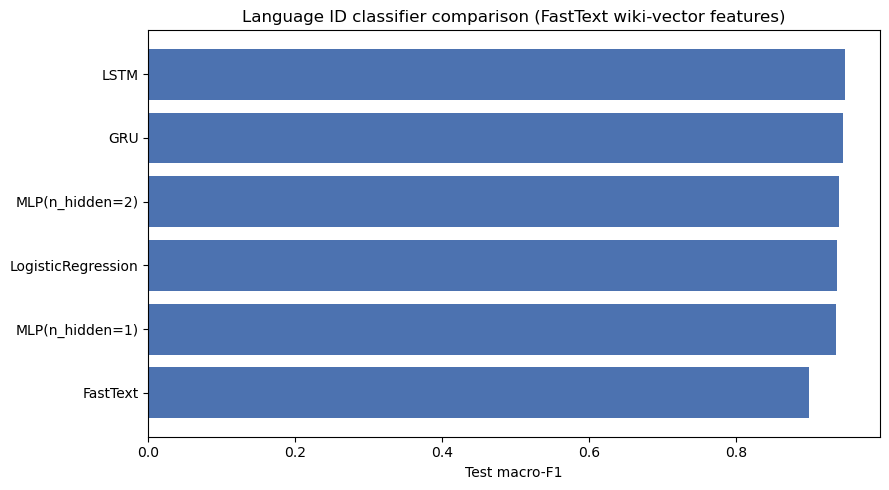

In [28]:
fig, ax = plt.subplots(figsize=(9, 5))
order = comparison_df.sort_values("test_macro_f1")
ax.barh(order["classifier"], order["test_macro_f1"], color="#4C72B0")
ax.set_xlabel("Test macro-F1")
ax.set_title("Language ID classifier comparison (FastText wiki-vector features)")
plt.tight_layout()
plt.show()


## 9. Save results

In [29]:
comparison_df.to_csv(os.path.join(ARTIFACTS_DIR, "classifier_comparison.csv"), index=False)

with open(os.path.join(ARTIFACTS_DIR, "test_predictions.pkl"), "wb") as f:
    pickle.dump({name: y_pred for name, y_pred in results.items()}, f)

ft_model.save_model(os.path.join(ARTIFACTS_DIR, "fasttext_supervised.bin"))

print("Saved classifier comparison table, test predictions, and the FastText model to", ARTIFACTS_DIR)


Saved classifier comparison table, test predictions, and the FastText model to lab6_artifacts
